# Clasificación. Parte I - Clasificación binaria.

Los sistemas de aprendizaje automático **supervisado** más comunes son los de **regresión** que predicen <u>valores</u> y **clasificación** que predicen <u>clases</u>.

Trabajan con el dataset MNNIST (Modified National Institute of Standards and Technology).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Carga de datos

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1)

## Exploración y visualización de datos

El dataset MNIST contiene 70000 imágenes de dígitos manuscritos.

In [3]:
mnist

{'data':        pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
 0           0       0       0       0       0       0       0       0       0   
 1           0       0       0       0       0       0       0       0       0   
 2           0       0       0       0       0       0       0       0       0   
 3           0       0       0       0       0       0       0       0       0   
 4           0       0       0       0       0       0       0       0       0   
 ...       ...     ...     ...     ...     ...     ...     ...     ...     ...   
 69995       0       0       0       0       0       0       0       0       0   
 69996       0       0       0       0       0       0       0       0       0   
 69997       0       0       0       0       0       0       0       0       0   
 69998       0       0       0       0       0       0       0       0       0   
 69999       0       0       0       0       0       0       0       0       0   
 
      

In [4]:
# Claves del diccionario

mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [5]:
# Descripción del dataset
mnist["DESCR"]

"**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  \n**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  \n**Please cite**:  \n\nThe MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  \n\nIt is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image by computing the center of mass of the pixels, and translating the image so as to position this point at the center of the 28x28 field.  

With some classification methods (particularly template-based methods, such as SVM and K-nearest neighbors), the error rate improves when the digits are centered by bounding box rather than center of mass. If you do this kind of pre-processing, you should report it in your publications. The MNIST database was constructed from NIST's NIST originally designated SD-3 as their training set and SD-1 as their test set. However, SD-3 is much cleaner and easier to recognize than SD-1. The reason for this can be found on the fact that SD-3 was collected among Census Bureau employees, while SD-1 was collected among high-school students. Drawing sensible conclusions from learning experiments requires that the result be independent of the choice of training set and test among the complete set of samples. Therefore it was necessary to build a new database by mixing NIST's datasets.  

The MNIST training set is composed of 30,000 patterns from SD-3 and 30,000 patterns from SD-1. Our test set was composed of 5,000 patterns from SD-3 and 5,000 patterns from SD-1. The 60,000 pattern training set contained examples from approximately 250 writers. We made sure that the sets of writers of the training set and test set were disjoint. SD-1 contains 58,527 digit images written by 500 different writers. In contrast to SD-3, where blocks of data from each writer appeared in sequence, the data in SD-1 is scrambled. Writer identities for SD-1 is available and we used this information to unscramble the writers. We then split SD-1 in two: characters written by the first 250 writers went into our new training set. The remaining 250 writers were placed in our test set. Thus we had two sets with nearly 30,000 examples each. The new training set was completed with enough examples from SD-3, starting at pattern # 0, to make a full set of 60,000 training patterns. Similarly, the new test set was completed with SD-3 examples starting at pattern # 35,000 to make a full set with 60,000 test patterns. Only a subset of 10,000 test images (5,000 from SD-1 and 5,000 from SD-3) is available on this site. The full 60,000 sample training set is available.

Downloaded from openml.org.

In [6]:
# Guarda la información en un fichero

with open("mnist_description.md", "w", encoding="utf-8") as f:
  f.write(mnist["DESCR"])

In [7]:
mnist["data"]

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
# ¿De qué tipo son los datos?

mnist["target"]

,class
0,5
1,0
2,4
3,1
4,9
...,...
69995,2
69996,3
69997,4
69998,5


In [9]:
mnist["target"].unique()

['5', '0', '4', '1', '9', '2', '3', '6', '7', '8']
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [10]:
X = mnist["data"]
y = mnist["target"]

In [11]:
# Tomamos un elemento cualquiera, por ejemplo el de la posición 22
print(y[22]) # la fila guarda información sobre un 9
print(X.loc[22, :]) # información de la imagen

9
pixel1      0
pixel2      0
pixel3      0
pixel4      0
pixel5      0
           ..
pixel780    0
pixel781    0
pixel782    0
pixel783    0
pixel784    0
Name: 22, Length: 784, dtype: int64


En la fila 22 tenemos el dígito 9.

In [12]:
X.describe()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
count,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,...,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.0,70000.0,70000.0,70000.0
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.197414,0.099543,0.046629,0.016614,0.012957,0.001714,0.0,0.0,0.0,0.0
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5.991206,4.256304,2.783732,1.561822,1.553796,0.320889,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,254.000000,254.000000,253.000000,253.000000,254.000000,62.000000,0.0,0.0,0.0,0.0


Cada fila de $X$ representa una imagen de $28 \times 28$ ($\sqrt{784}$).

Los píxeles tienen un valor entre 0 y 255 según la intensidad.

In [13]:
# Pintamos la fila 22

example_digit = X.loc[22, :].to_numpy()
example_digit_image = example_digit.reshape(28, 28)

print("Dígito en una línea de 784 elementos: ", example_digit)
print("\nDígito en 28 filas por 28 columnas: ", example_digit_image)

Dígito en una línea de 784 elementos:  [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0  31 144 250 254 166   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0  98 241 204  97 126 253
  40   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   6

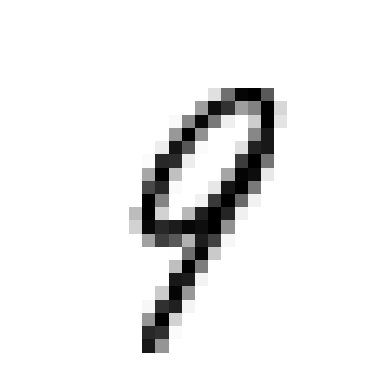

In [14]:
plt.imshow(example_digit_image, cmap="binary")
plt.axis("off")
plt.show()

3


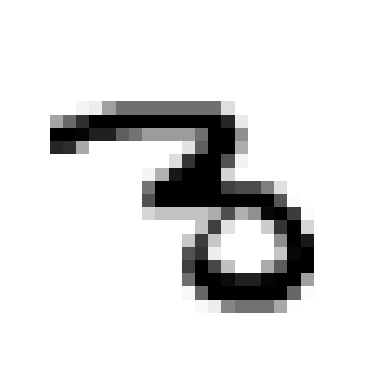

In [15]:
# Probamos con otra fila, por ejemplo la 30

example_digit_v2 = X.loc[30, :].to_numpy()
example_digit_image_v2 = example_digit_v2.reshape(28, 28)
print(y[30])
plt.imshow(example_digit_image_v2, cmap="binary")
plt.axis("off")
plt.show()

In [16]:
type(y)

pandas.core.series.Series

In [17]:
y.describe()

,class
count,70000
unique,10
top,1
freq,7877


Vamos a convertir los valores de $y$ a números enteros.

In [18]:
y = y.to_numpy()
y = y.astype(np.uint8) # entero de 8 bits
print(type(y))
print(y.dtype)

<class 'numpy.ndarray'>
uint8


## Creación del conjunto de datos de entrenamiento y de los datos de prueba

El dataset MNIST viene preparado de tal forma que las primeras 60000 imágenes son de entrenamiento y las últimas 10000 con para hacer pruebas.

In [19]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

## Entrenamiento del modelo (Clasificador binario)

En esta primera parte, vamos a crear un clasificador binario, que diga si un dígito es o no el 5.

In [20]:
y_train = (y_train == 5)
y_train

array([ True, False, False, ...,  True, False, False], shape=(60000,))

In [21]:
y_test = (y_test == 5)
y_test

array([False, False, False, ..., False,  True, False], shape=(10000,))

Vamos a utilizar los algoritmos *Stochastic Gradient Descent* y *Linear Support Vector Classification** (este último se supone que es mejor cuando tenemos menos de 10000 muestras).

### Modelo SGDCClassifier

In [22]:
from sklearn.linear_model import SGDClassifier

model_sgdc = SGDClassifier(random_state=24)
model_sgdc.fit(X_train, y_train)

SGDClassifier(random_state=24)

Vamos a comprobar si el modelo puede predecir bien los dos ejemplos anteriores.

In [23]:
model_sgdc.predict([example_digit, example_digit_v2])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SGDClassifier was fitted with feature names
  warnings.warn(


array([False, False])

Efectivamente, el 9 y el 3 no son el dígito 5.

Vamos a probar con un número que sabemos que es un 5.

In [24]:
print(y[11])
model_sgdc.predict([X.loc[11, :].to_numpy()])

5


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SGDClassifier was fitted with feature names
  warnings.warn(


array([ True])

In [25]:
y

array([5, 0, 4, ..., 4, 5, 6], shape=(70000,), dtype=uint8)

## Rendimiento del modelo (SGDClassifier)

## Aciertos y fallos

Usamos los datos de prueba para hacer predicciones y comprobamos si son correctas.

In [26]:
# Número de aciertos y número de fallos con las predicciones sobre el conjunto de test
y_test_pred = model_sgdc.predict(X_test)
success = (y_test_pred == y_test).sum()
fail = (y_test_pred != y_test).sum()
print("Aciertos: ", success)
print("Fallos: ", fail)
print("Precisión: ", (success / (success + fail)) * 100, "%") # Porcentaje de aciertos respecto al total

Aciertos:  9656
Fallos:  344
Precisión:  96.56 %


### Validación cruzada (cross validation)

In [27]:
from sklearn.model_selection import cross_val_score

cross_val_score(model_sgdc, X_train, y_train, cv=5)

array([0.95966667, 0.96483333, 0.9655    , 0.95      , 0.96016667])

Hemos obtenido una precisión del 95% o más en cada caso.

### Matriz de confusión

Cada columna de la matriz representa el número de predicciones de cada clase, mientras que cada fila representa a las instancias reales.

[Matriz de confusión](https://es.wikipedia.org/wiki/Matriz_de_confusi%C3%B3n)

<img src="https://drive.google.com/uc?id=1roENWlclEGwOBJ73r2b9VuVPt9hMkTWZ">

In [28]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_test_pred)

array([[9047,   61],
       [ 283,  609]])

Un dato de eficacia que se suele utilizar es *precission*.

$precission = \frac{TP}{TP + FP}$

In [29]:
precission = 609 / (609 + 61)
precission

0.908955223880597

Otro dato que se usa es el llamado *recall* (sensibilidad o ratio de verdaderos positivos).

Responde a la pregunta: "De todos los casos que realmente son positivos, ¿cuántos detectó el modelo?"

Es la métrica clave cuando **omitir un caso positivo (falso negativo) tiene consecuencias graves**, como en diagnóstico médico, detección de fraude o seguridad.

$recall = \frac{TP}{TP + FN}$

In [30]:
recall = 609 / (609 + 283)
recall

0.6827354260089686

## Modelo LinearSVC

In [31]:
from sklearn.svm import LinearSVC

model_lsvc = LinearSVC(random_state=24)
model_lsvc.fit(X_train, y_train)

LinearSVC(random_state=24)

In [32]:
model_lsvc.predict([example_digit, example_digit_v2])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearSVC was fitted with feature names
  warnings.warn(


array([False, False])

In [33]:
model_lsvc.predict([X.loc[11, :].to_numpy()])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearSVC was fitted with feature names
  warnings.warn(


array([ True])

In [34]:
y_test_pred = model_lsvc.predict(X_test)
success = (y_test_pred == y_test).sum()
fail = (y_test_pred != y_test).sum()
print("Aciertos: ", success)
print("Fallos: ", fail)
print("Precisión: ", (success / (success + fail)) * 100, "%")

Aciertos:  9761
Fallos:  239
Precisión:  97.61 %


In [35]:
cross_val_score(model_lsvc, X_train, y_train, cv=5)

array([0.97491667, 0.97233333, 0.97291667, 0.97066667, 0.97441667])

### Comparativa de Modelos

| Modelo | Aciertos | Fallos | Precisión | Validación Cruzada |
| :--- | :---: | :---: | :---: | :---: |
| **SGDClassifier** | 9656 | 344 | 96.56 % | ~95.0% a 96.5% |
| **LinearSVC** | 9761 | 239 | 97.61 % | +97.0% |

*El modelo `LinearSVC` ofrece un rendimiento ligeramente superior en este conjunto de datos de prueba.*